# Corner Chance Planner: what the data says and what the tool does

**Who this is for:** coaching and analysis staff, and anyone deciding whether to use the Corner Chance Planner.

**The question:** when we take an attacking corner, which choices (delivery, target and where our players stand) make a good chance more likely?

## In one minute

- **A corner works in two steps:** win the first ball, then turn it into a chance. About **1 in 3** first balls are won, and about **2 in 3** of those become a good chance. Overall, **1 in 3** corners creates a good chance.
- **The first step can be predicted; the overall outcome only roughly.** On competitions it never saw, the model ranks corners correctly about 68% of the time for winning the first ball (a coin flip is 50%). The original system's numbers did no better than a coin flip once tested the same way.
- **The target is a trade-off.** Far-post balls are won most often (76%), but won balls in the middle become chances far more often (80% vs 46%).
- **Spare attackers around the penalty spot help.** 2 or more spare attackers there: 42% good chances, against 28% with none.
- **The opponent's defensive shape makes no clear difference** once we account for the competition, and **counter-attack risk can't be predicted** from the setup.
- **The tool** shows real past corners first and the model second, with a 90% range on every number.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, Markdown, display

import overview_helpers as oh

oh.style()
pd.set_option("display.max_colwidth", 60)

corners = oh.load_corners()
CHAIN_NAMES = dict(oh.CHAIN)
evaluation = oh.load_evaluation()
per_competition = oh.load_per_competition()

## 1. The data

Every corner with a StatsBomb 360 freeze frame: the positions of all visible players at the moment the corner is taken. MLS 2023 and the African Cup of Nations 2023 are left out because their freeze frames are missing or show too few players.

In [2]:
data = (
    corners.groupby(["competition", "football", "level"])
    .agg(corners=("match_id", "size"), matches=("match_id", "nunique"), seasons=("season_id", "nunique"))
    .reset_index()
    .sort_values(["football", "corners"], ascending=[True, False])
    .rename(columns={"competition": "Competition", "football": "Football", "level": "Type",
                     "corners": "Corners", "matches": "Matches", "seasons": "Seasons"})
)
display(data.style.hide(axis="index"))
mens, womens = (corners.football == "Men's").sum(), (corners.football == "Women's").sum()
display(Markdown(
    f"**{len(corners)} corners** from **{corners.match_id.nunique()} matches** in "
    f"**{corners.competition.nunique()} competitions** ({mens} men's, {womens} women's)."
))

Competition,Football,Type,Corners,Matches,Seasons
UEFA Euro,Men's,International,249,79,2
Bundesliga,Men's,Club,146,29,1
FIFA World Cup,Men's,International,110,46,1
Ligue 1,Men's,Club,82,40,2
La Liga,Men's,Club,61,26,1
UEFA Women's Euro,Women's,International,128,49,2
FIFA Women's World Cup,Women's,International,103,37,1


**879 corners** from **306 matches** in **7 competitions** (648 men's, 231 women's).

## 2. How a corner is measured

We follow each corner through two steps:

1. **First ball won:** an attacker plays the ball first after the delivery (a header, a shot, a flick-on or controlling it), rather than a defender or the keeper. Corners that go straight out or end in a foul are left out of this step.
2. **Good chance:** a shot worth at least 0.04 expected goals (xG) while we keep the ball, within 60 seconds.

These combine into the overall result:

> **good chance = first ball won × good chance after winning it + first ball lost × good chance after losing it**

In [3]:
overall = {}
rows = []
for m, name in oh.CHAIN[:2] + [("chance_if_lost", "2 · Good chance after losing it")] + oh.CHAIN[2:]:
    y = corners[m].dropna()
    p, lo, hi = oh.wilson(y.sum(), len(y))
    overall[m] = p
    rows.append({"Step": name, "Rate": f"{p:.0%}", "90% range": f"{lo:.0%} to {hi:.0%}", "Real corners": f"{int(y.sum())} of {len(y)}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

Step,Rate,90% range,Real corners
1 · First ball won,35%,33% to 38%,284 of 801
2 · Good chance after winning it,65%,60% to 70%,185 of 284
2 · Good chance after losing it,18%,15% to 21%,92 of 517
= Good chance overall,32%,30% to 35%,283 of 879


Winning the first ball matters most: corners where we win it become a good chance about **two thirds** of the time, against fewer than **1 in 5** when we lose it.

## 3. Can a model predict it?

Every model is tested on competitions it was **not** trained on: train on six competitions, predict the seventh, and repeat. AUC is how often the model ranks a corner that worked above one that didn't; **0.5 is a coin flip**.

Step,AUC (unseen competitions),Brier skill
1 · First ball won,0.68,+0.087
2 · Good chance after winning it,0.68,+0.083
2 · Good chance after losing it,0.58,+0.020
= Good chance overall,0.57,+0.014


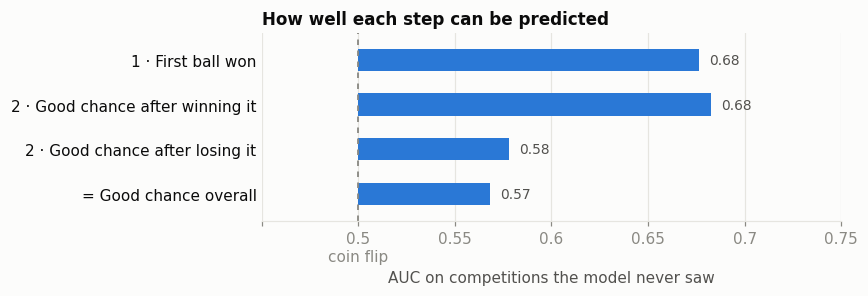

In [4]:
fig, steps = oh.plot_model_steps(evaluation)
display(steps.style.hide(axis="index").format({"AUC (unseen competitions)": "{:.2f}", "Brier skill": "{:+.3f}"}))

- **Tested:** winning the first ball and the chance after winning it are predicted well above a coin flip.
- **Weak:** what happens after losing the first ball (second balls, scrambles) is close to unpredictable.
- So the overall good-chance estimate is a **rough guide**, and the tool labels it that way. Brier skill is how much better than "always guess the average" the model is; above 0 means it adds something.

The first-ball model holds up in most competitions it was tested on:

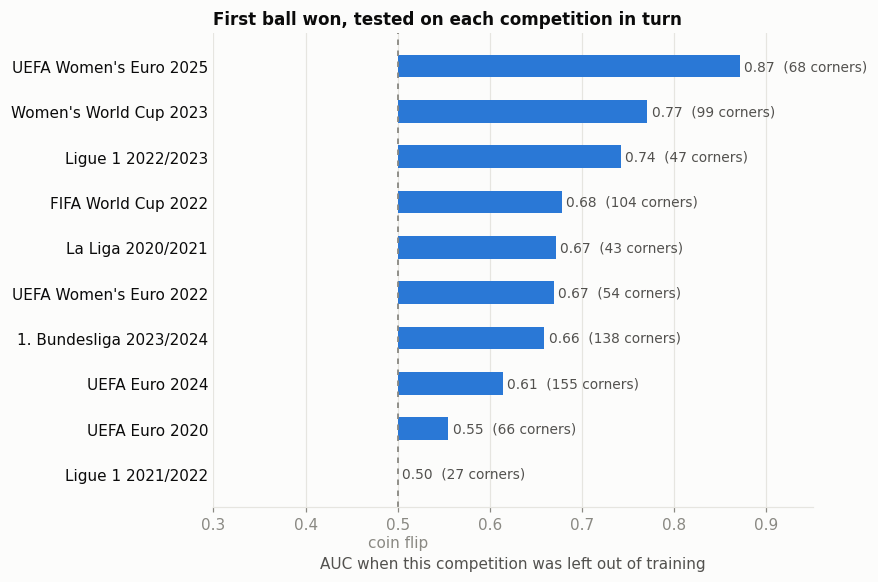

In [5]:
fig = oh.plot_per_competition(per_competition)

### Compared with the original system

The original system reported AUC 0.61 for chances and 0.75 for shots conceded, but those were measured on the same corners it was trained on. Re-tested the current way (on unseen competitions), it did no better than a coin flip, and its probabilities were badly inflated: it predicted a 42% chance of conceding a shot when the real rate is 5%.

*The original system's numbers below come from re-scoring its saved models on its own data (749 corners) during the rebuild. Its outcomes were defined slightly differently (any shot within 60 seconds), so treat the comparison as indicative.*

Outcome,Original AUC,Original Brier skill,Current AUC,Current Brier skill
First ball won,not measured,not measured,0.68,+0.087
Good chance created,0.52,-0.144,0.57,+0.014
Shot conceded,0.56,-3.29,0.41,-0.000


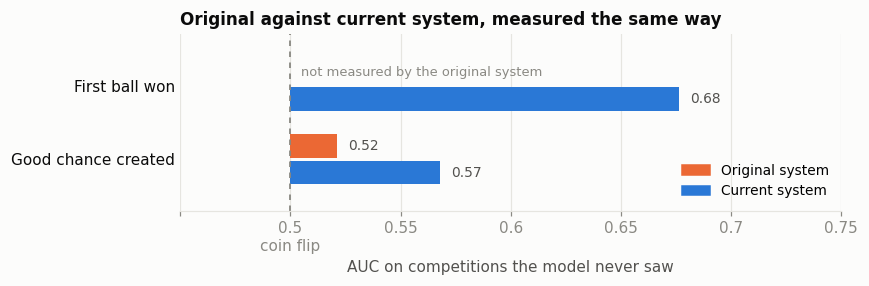

In [6]:
fc = evaluation.query("target == 'first_contact_attack' and scheme == 'leave_one_competition_out' and model == 'full_model'").iloc[0]
ch = evaluation.query("target == 'chance_chain' and scheme == 'leave_one_competition_out' and model == 'chain_model'").iloc[0]
sc = evaluation.query("target == 'shot_against_any' and scheme == 'leave_one_competition_out' and model == 'full_model'").iloc[0]

fig = oh.plot_old_vs_new([
    ("First ball won", None, fc.roc_auc),
    ("Good chance created", 0.521, ch.roc_auc),
])

comparison = pd.DataFrame([
    ["First ball won", "not measured", "not measured", f"{fc.roc_auc:.2f}", f"{fc.brier_skill:+.3f}"],
    ["Good chance created", "0.52", "-0.144", f"{ch.roc_auc:.2f}", f"{ch.brier_skill:+.3f}"],
    ["Shot conceded", "0.56", "-3.29", f"{sc.roc_auc:.2f}", f"{sc.brier_skill:+.3f}"],
], columns=["Outcome", "Original AUC", "Original Brier skill", "Current AUC", "Current Brier skill"])
display(comparison.style.hide(axis="index"))

A negative Brier skill means the original system's probabilities were **worse than always quoting the average**. The current models are calibrated: when they say 30%, about 30% of such corners work. Neither system can predict shots conceded, so the tool no longer shows them.

## 4. What makes a difference

Each chart follows one choice through the two steps, all on the same 0 to 100% scale. These are counts of real corners, no model involved.

,1 · First ball won,2 · Good chance after winning it,= Good chance overall
Near post,38% (89 of 233),51% (45 of 89),26% (71 of 272)
Middle,29% (147 of 505),80% (118 of 147),35% (189 of 537)
Far post,76% (48 of 63),46% (22 of 48),33% (23 of 70)


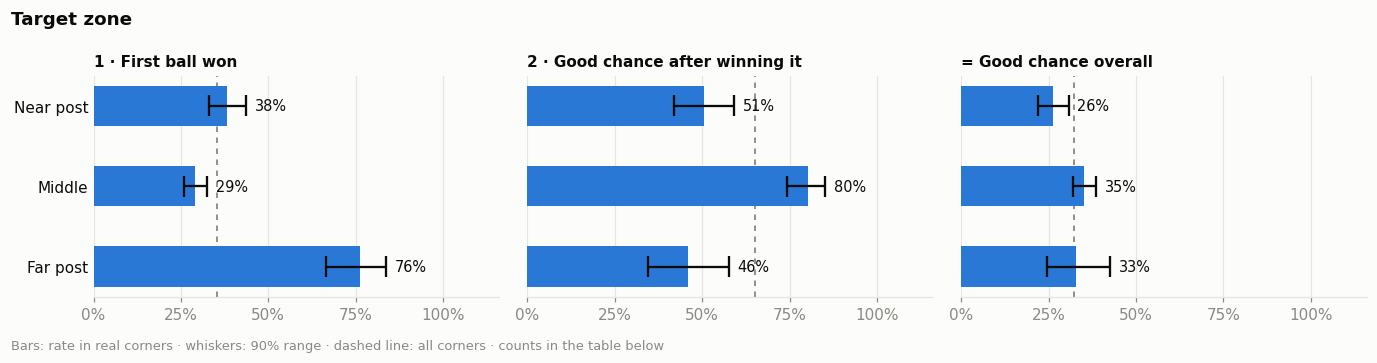

In [7]:
zone = oh.rate_table(corners, "end_zone", [m for m, _ in oh.CHAIN],
                     {"near": "Near post", "central": "Middle", "far": "Far post"})
fig = oh.plot_chain(zone, overall, "Target zone")
display(oh.readable(zone, CHAIN_NAMES))

**The target is a trade-off.** Far-post balls are won most often, but they are met far from goal, so few become chances. Middle balls are hard to win, but when they are won they usually become a chance. Overall, aiming at the middle creates the most good chances.

,1 · First ball won,2 · Good chance after winning it,= Good chance overall
Inswinger,29% (132 of 459),76% (100 of 132),34% (163 of 484)
Outswinger,41% (90 of 220),62% (56 of 90),33% (75 of 230)
Straight,54% (32 of 59),56% (18 of 32),41% (26 of 64)
Short routine,22% (2 of 9),100% (2 of 2),28% (5 of 18)


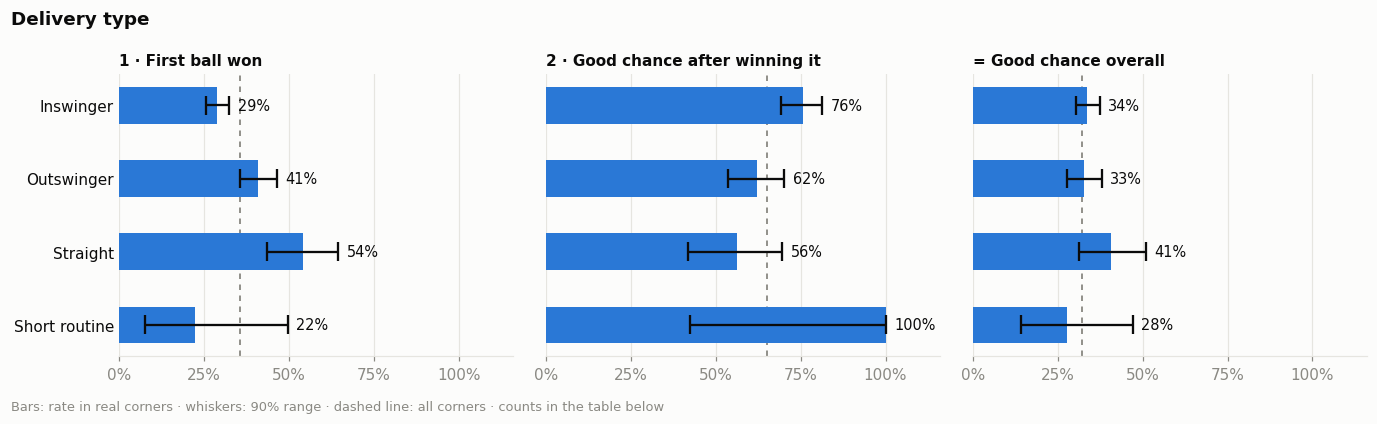

In [8]:
delivery = oh.rate_table(corners, "route", [m for m, _ in oh.CHAIN],
                         {"inswing": "Inswinger", "outswing": "Outswinger", "straight": "Straight", "short": "Short routine"})
fig = oh.plot_chain(delivery, overall, "Delivery type")
display(oh.readable(delivery, CHAIN_NAMES))

**Inswingers are the hardest to win** (29%): most are met inside the 6-yard box, where the keeper and the packed box dominate. Straight and outswinging deliveries win the first ball more often. Short routines are rare in this data, so their bars are wide.

,1 · First ball won,2 · Good chance after winning it,= Good chance overall
None,36% (193 of 543),60% (115 of 193),28% (168 of 602)
1 spare,38% (51 of 134),73% (37 of 51),41% (59 of 145)
2 or more,32% (40 of 124),82% (33 of 40),42% (56 of 132)


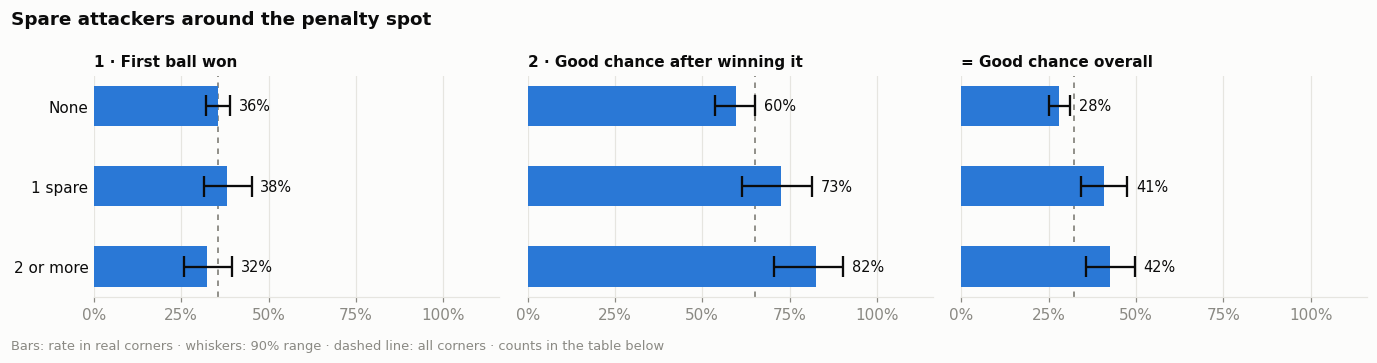

In [9]:
spare = corners.assign(spare=corners.free_att_spot.clip(upper=2).round())
spare_t = oh.rate_table(spare, "spare", [m for m, _ in oh.CHAIN],
                        {0.0: "None", 1.0: "1 spare", 2.0: "2 or more"})
fig = oh.plot_chain(spare_t, overall, "Spare attackers around the penalty spot")
display(oh.readable(spare_t, CHAIN_NAMES))

**Spare attackers around the penalty spot** (attackers left over once each defender in that zone takes one) don't help win the first ball, but once it is won they turn it into a chance much more often (82% with 2 or more spare, against 60% with none), most likely because there is a free player to meet the knock-down.

## 5. What makes little difference

### The opponent's defensive shape

We group defences by two simple rules from the freeze frame: is anyone on a post, and do the box defenders stand deep or high. A single snapshot can't show man-marking or zonal marking, so the groups describe positions only.

In [10]:
shape = oh.rate_table(corners, "A_name", ["first_contact_attack", "chance_for"],
                      {s: s for s in ["Posts covered", "Deep line", "High line"]})
display(oh.readable(shape, {"first_contact_attack": "First ball won", "chance_for": "Good chance"}))

by_football = oh.rate_table(corners.assign(key=corners.A_name + " · " + corners.football), "key", ["chance_for"],
                            {f"{s} · {f}": f"{s} · {f}" for f in ["Men's", "Women's"] for s in ["Posts covered", "Deep line", "High line"]})
display(Markdown("**Good chances by shape, split by men's and women's football:**"))
display(oh.readable(by_football, {"chance_for": "Good chance"}))

,First ball won,Good chance
Posts covered,36% (54 of 148),41% (64 of 157)
Deep line,34% (115 of 334),33% (116 of 356)
High line,36% (115 of 319),28% (103 of 366)


**Good chances by shape, split by men's and women's football:**

,Good chance
Posts covered · Men's,25% (13 of 53)
Deep line · Men's,30% (81 of 271)
High line · Men's,28% (90 of 324)
Posts covered · Women's,49% (51 of 104)
Deep line · Women's,41% (35 of 85)
High line · Women's,31% (13 of 42)


"Posts covered" looks best overall, but that is because it is mostly used in women's tournaments, where every kind of corner creates more chances. Among men's corners it is actually the lowest. Once the competition is accounted for, **the shape makes no clear difference**, and the best setup is the same against every shape. In the tool, the shape only changes which real corners you are compared with.

### Keeping players back

Does leaving more players outside the box reduce shots conceded?

In [11]:
rest = corners.assign(rest=corners.n_rest_defence.clip(lower=2, upper=5))
rest_t = oh.rate_table(rest, "rest", ["shot_against_any"], {2: "2 or fewer", 3: "3", 4: "4", 5: "5 or more"})
display(oh.readable(rest_t, {"shot_against_any": "Shot conceded"}))

,Shot conceded
2 or fewer,5% (8 of 149)
3,5% (15 of 313)
4,6% (10 of 170)
5 or more,3% (8 of 247)


Shots conceded stay around **3 to 6%** however many players stay back, and no model could predict them better than the average. So the tool doesn't show counter-attack risk.

### Men's and women's football

The one context that clearly changes the numbers is men's versus women's football. The difference sits almost entirely in what happens **after the first ball is lost**:

In [12]:
football = oh.rate_table(corners, "football", ["first_contact_attack", "chance_if_won", "chance_if_lost", "chance_for"],
                         {"Men's": "Men's", "Women's": "Women's"})
display(oh.readable(football, {
    "first_contact_attack": "1 · First ball won",
    "chance_if_won": "2 · Good chance after winning it",
    "chance_if_lost": "2 · Good chance after losing it",
    "chance_for": "= Good chance overall",
}))

,1 · First ball won,2 · Good chance after winning it,2 · Good chance after losing it,= Good chance overall
Men's,34% (199 of 580),64% (127 of 199),14% (52 of 381),28% (184 of 648)
Women's,38% (85 of 221),68% (58 of 85),29% (40 of 136),43% (99 of 231)


Women's corners produce good chances after a lost first ball twice as often, so second balls matter more. The best setup is still the same. All women's data comes from international tournaments, so this may partly be a tournament effect.

## 6. The Corner Chance Planner

Run it with `python app.py` and open http://127.0.0.1:7860 (see the README).

### Planner

Set up a corner on the left. On the right, the **Real corners** tab shows what happened in similar past corners, and the **Model** tab shows the estimate for your exact setup. Each tab breaks the result into the two steps. Quick wins suggest single changes that the models agree help and that real corners don't contradict.

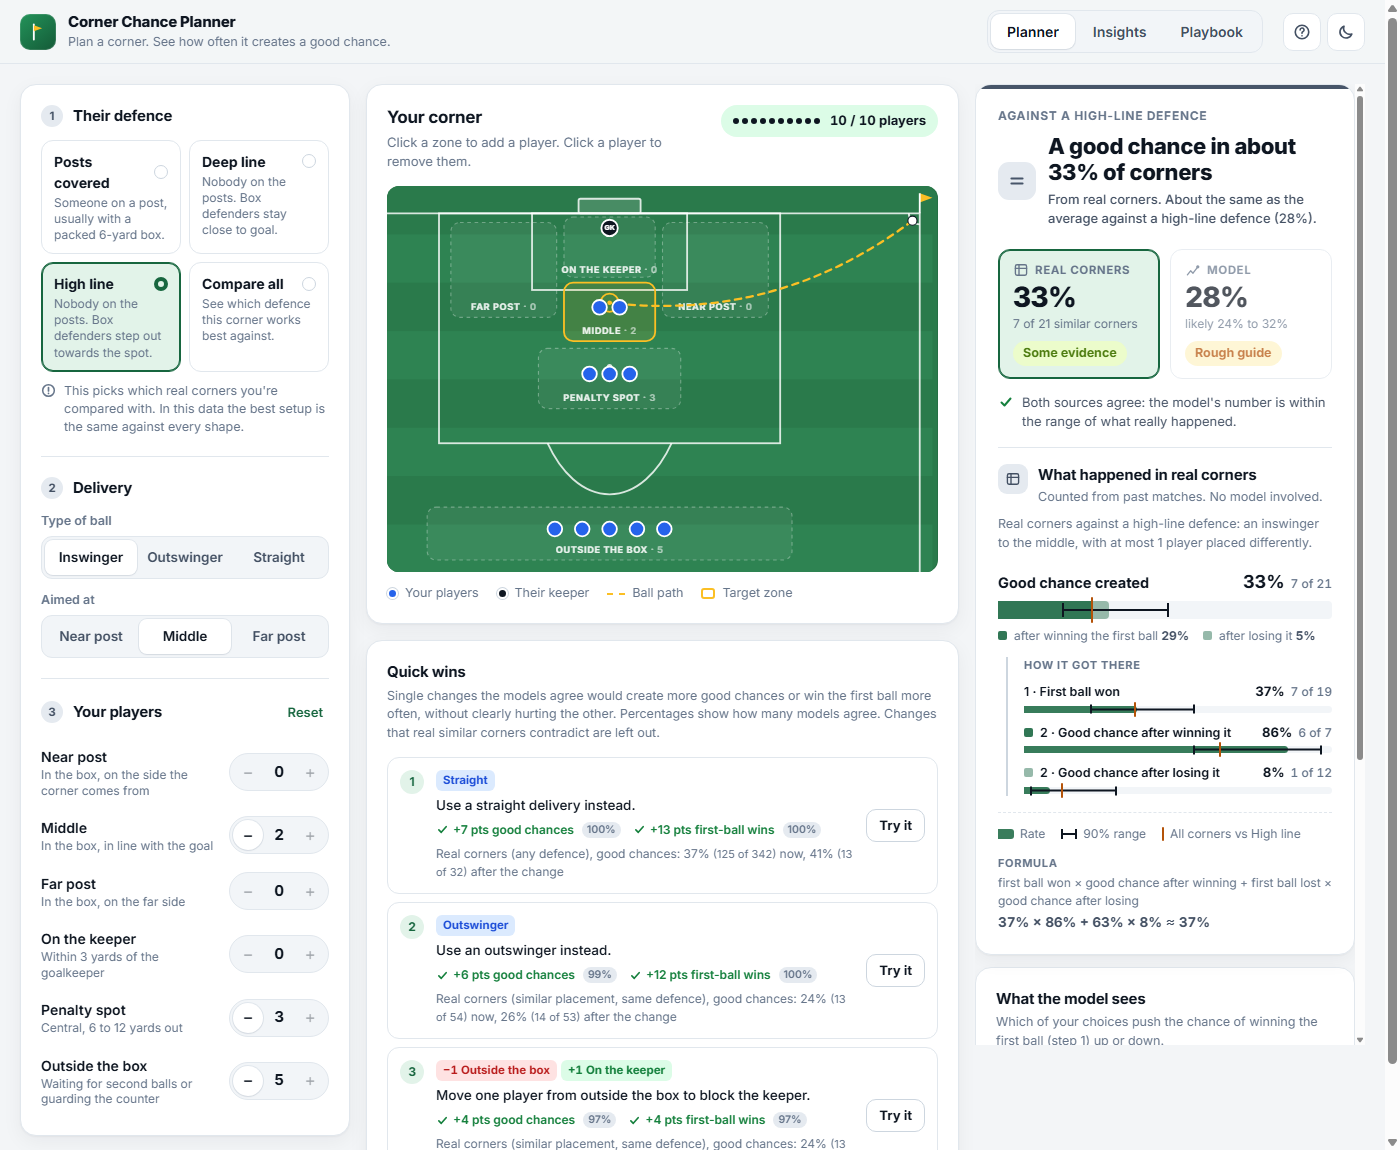

In [13]:
display(Image(filename="images/planner.png", width=1000))

### Insights and Playbook

**Insights** shows the findings above, organised by the two steps. **Playbook** groups real corners by delivery, target and how many players attack the box, ranks them by good chances, and opens a group's average setup in the planner.

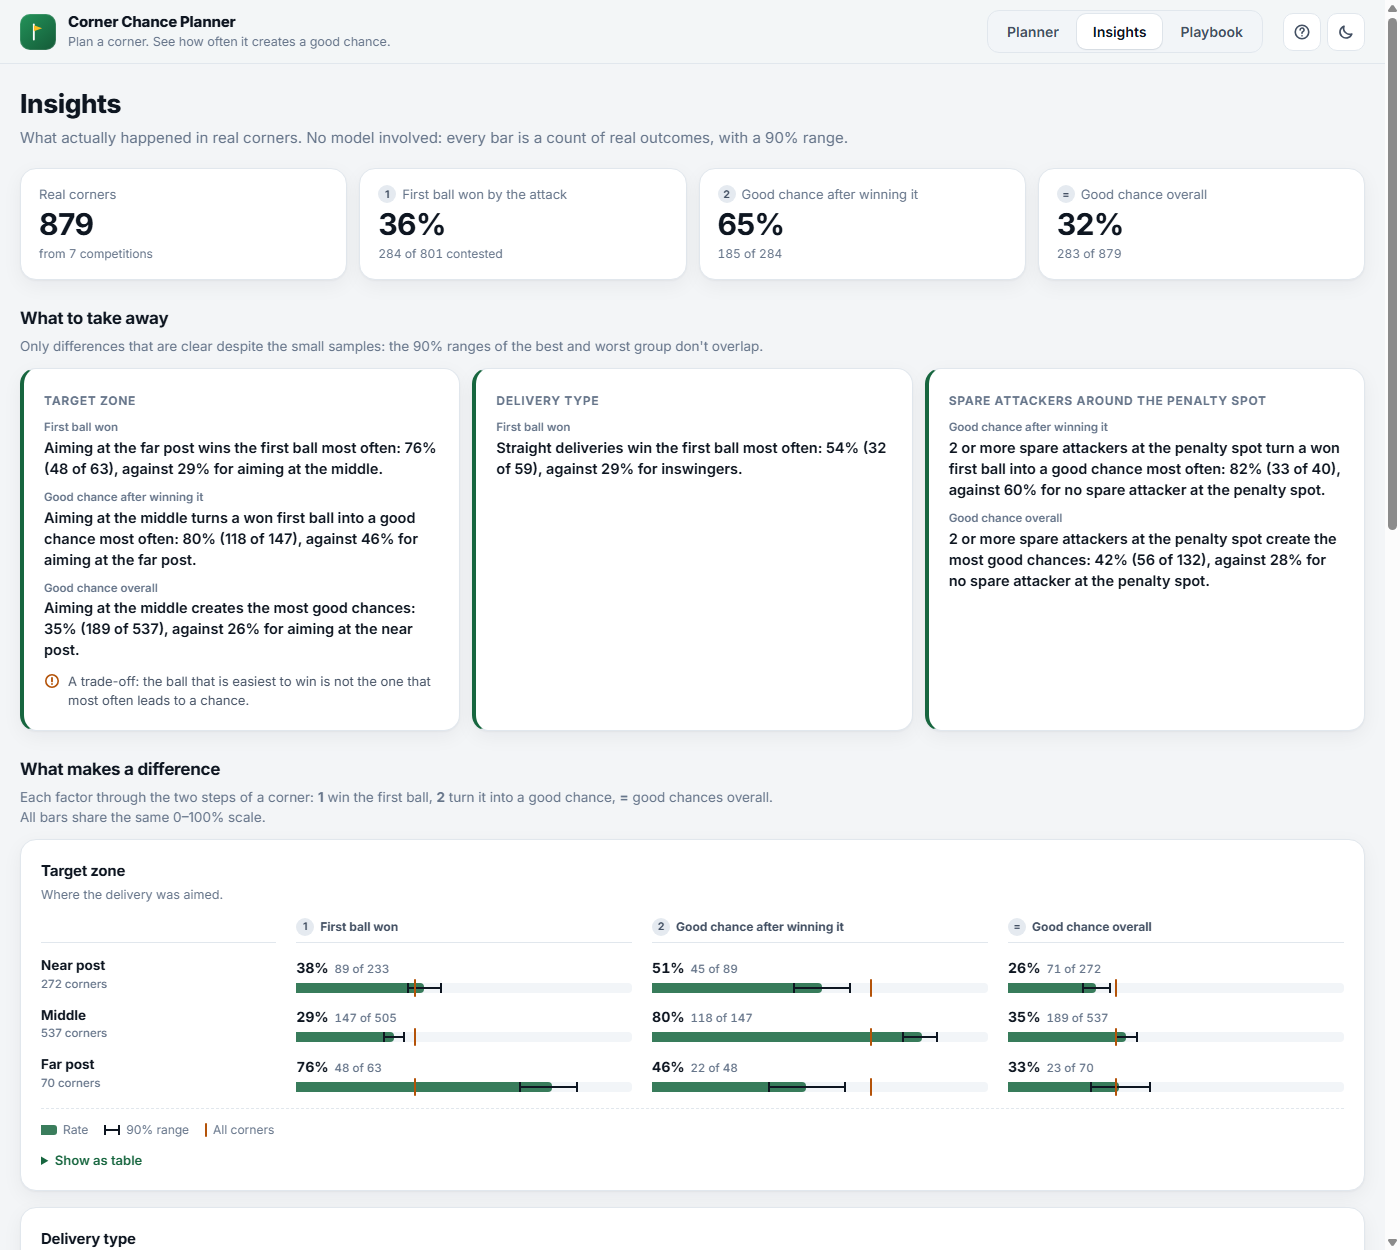

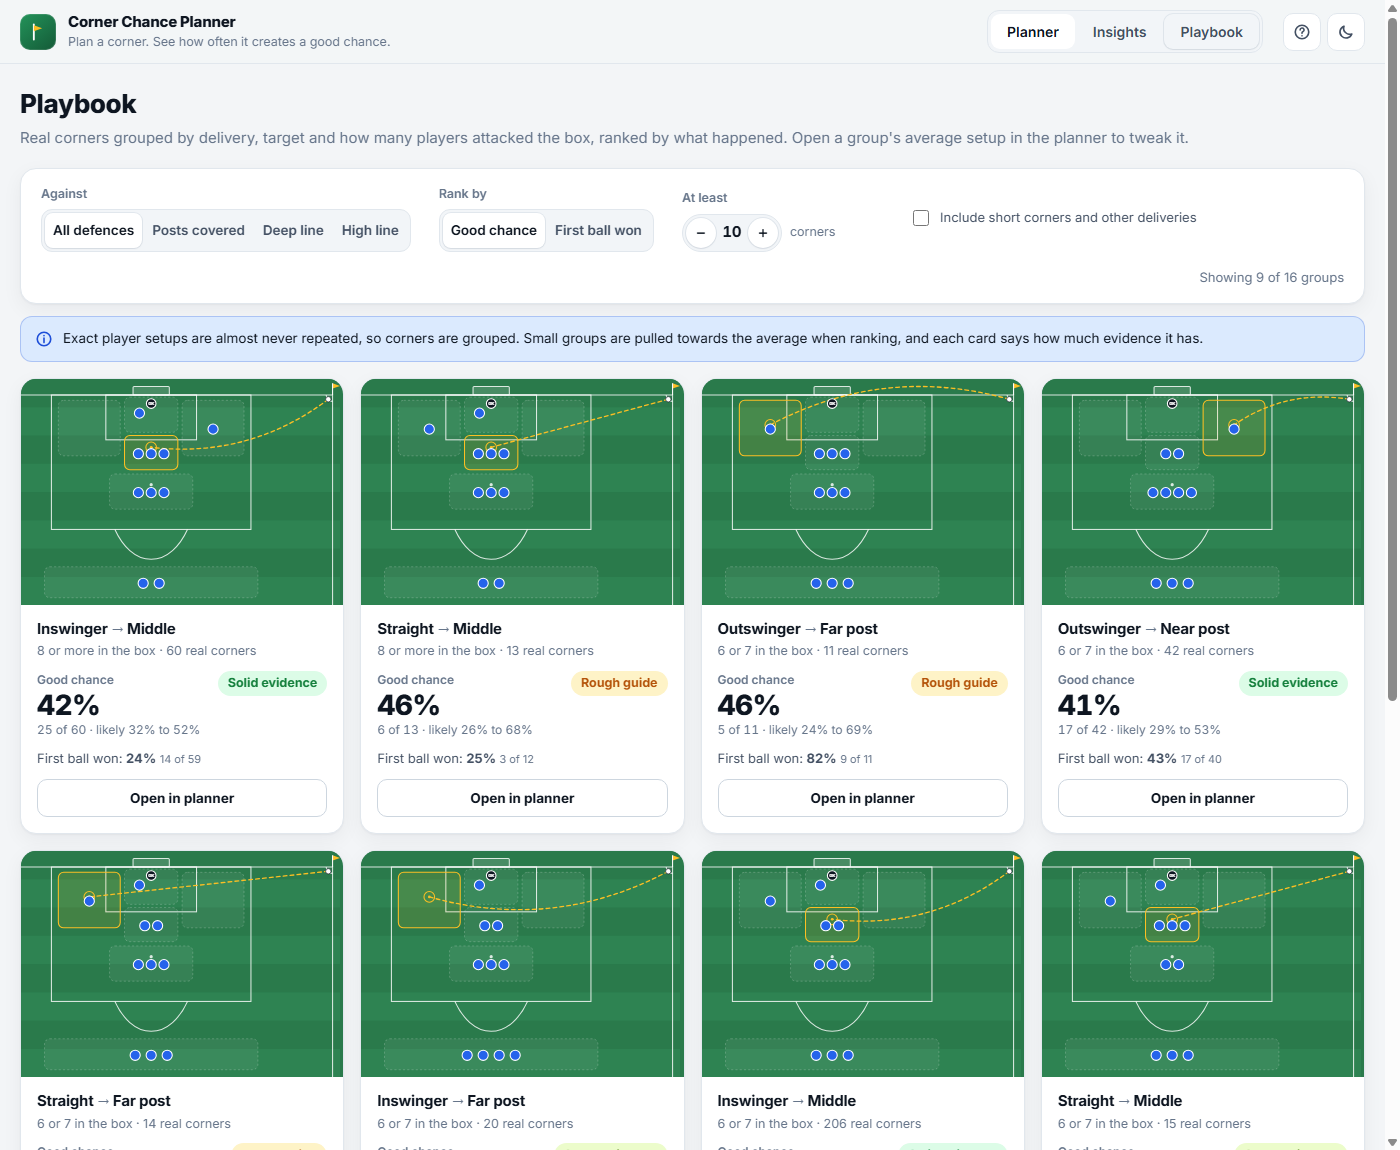

In [14]:
display(Image(filename="images/insights.png", width=1000))
display(Image(filename="images/playbook.png", width=1000))

### A suggested walkthrough

1. Open the planner with the default setup: an inswinger to the middle against a high line.
2. Switch between the **Real corners** and **Model** tabs, and point out the two steps and the formula.
3. Apply the top quick win with **Try it**, then **Undo**.
4. Change the target to the far post: the first ball is won more often, but fewer good chances follow.
5. Open **Insights** for the takeaways, then **Playbook** and open a group in the planner.

## 7. Limitations

- **Sample size:** 879 corners. Exact player setups are almost never repeated, and most teams defend only a handful of corners (a median of 5), so advice for a specific opponent isn't possible yet.
- **Freeze frames:** one snapshot at the moment of the corner. They show positions, not runs or marking, and don't identify players, so individual matchups can't be modelled.
- **Where the ball lands** is recorded where it was first touched, not where the taker aimed.
- **Competitions:** all women's data comes from international tournaments; there is no women's club football.
- **Outcomes after a lost first ball** and counter-attacks are close to unpredictable from the setup.

## 8. What would make it better

- **More corners**, for example more seasons or the club's own matches, would allow opponent profiles and more reliable groups.
- **Tracking data** (player movement, not just one snapshot) would show runs and marking.
- **Player identities** in the freeze frames would allow "our best header against their weakest defender".